In [ ]:
import marimo as mo
import pandas as pd
from scripts.extract_dataset import group_by_last_author
from scripts.iclr_analysis import compute_text_embeddings_SBERT, download_autotokenizer, compute_tsne
import matplotlib.pyplot as plt
import numpy as np

# Importing the ICLR OpenReview Dataset

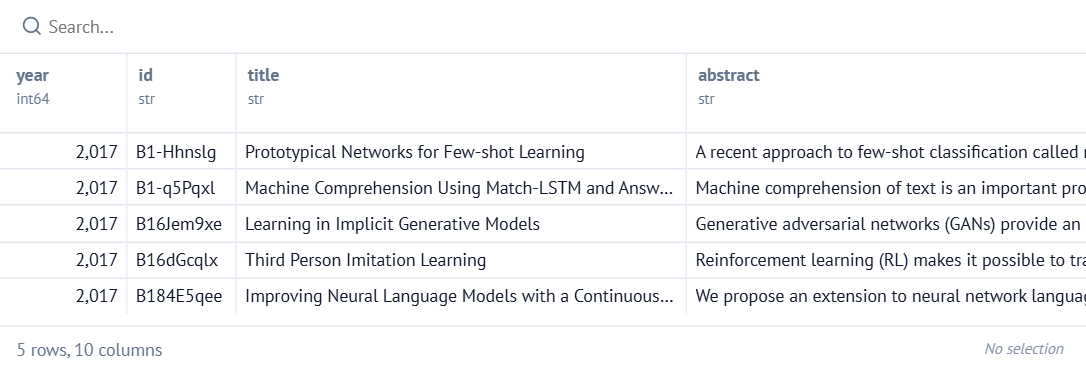

In [ ]:
iclr2026v1 = pd.read_parquet("data/iclr26v1.parquet")
iclr2026v1.head()

# Group Papers by Principal Investigator (Last Listed Author)

Here we are assuming that the last author listed in `authors` is the Principal Investigators (PIs). We want to analyze the PIs because they have more publications than a new researcher and have better intuition on whether to stay in a research topic or to branch out.

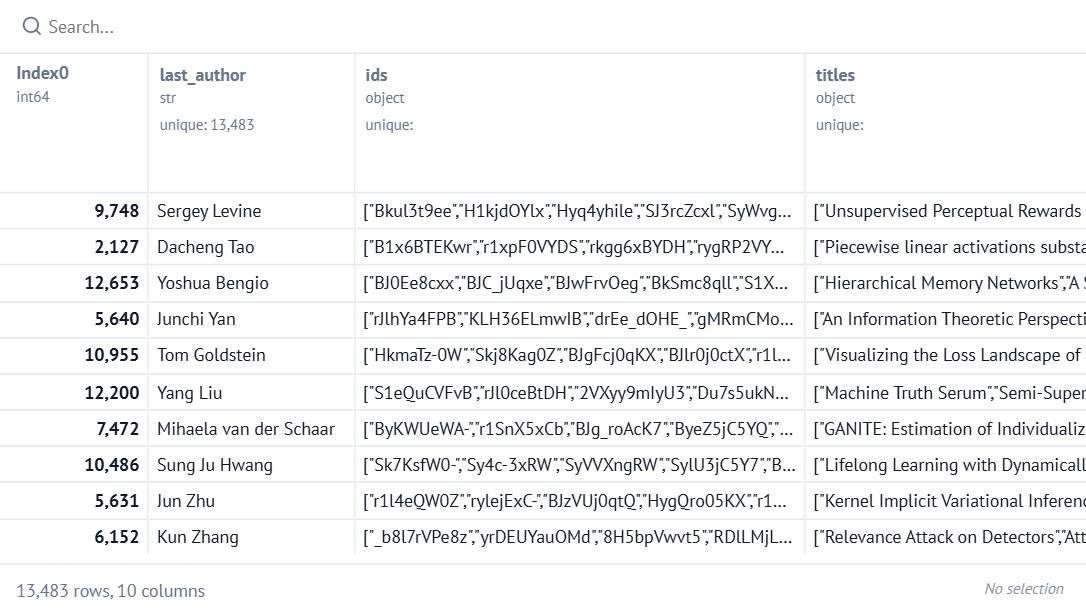

In [ ]:
last_author_df = group_by_last_author(iclr2026v1)
last_author_df.sort_values("num_papers", ascending=False)

# Initial Analysis

## Visualization: Complementary Cumulative Distribution Function (CCDF)

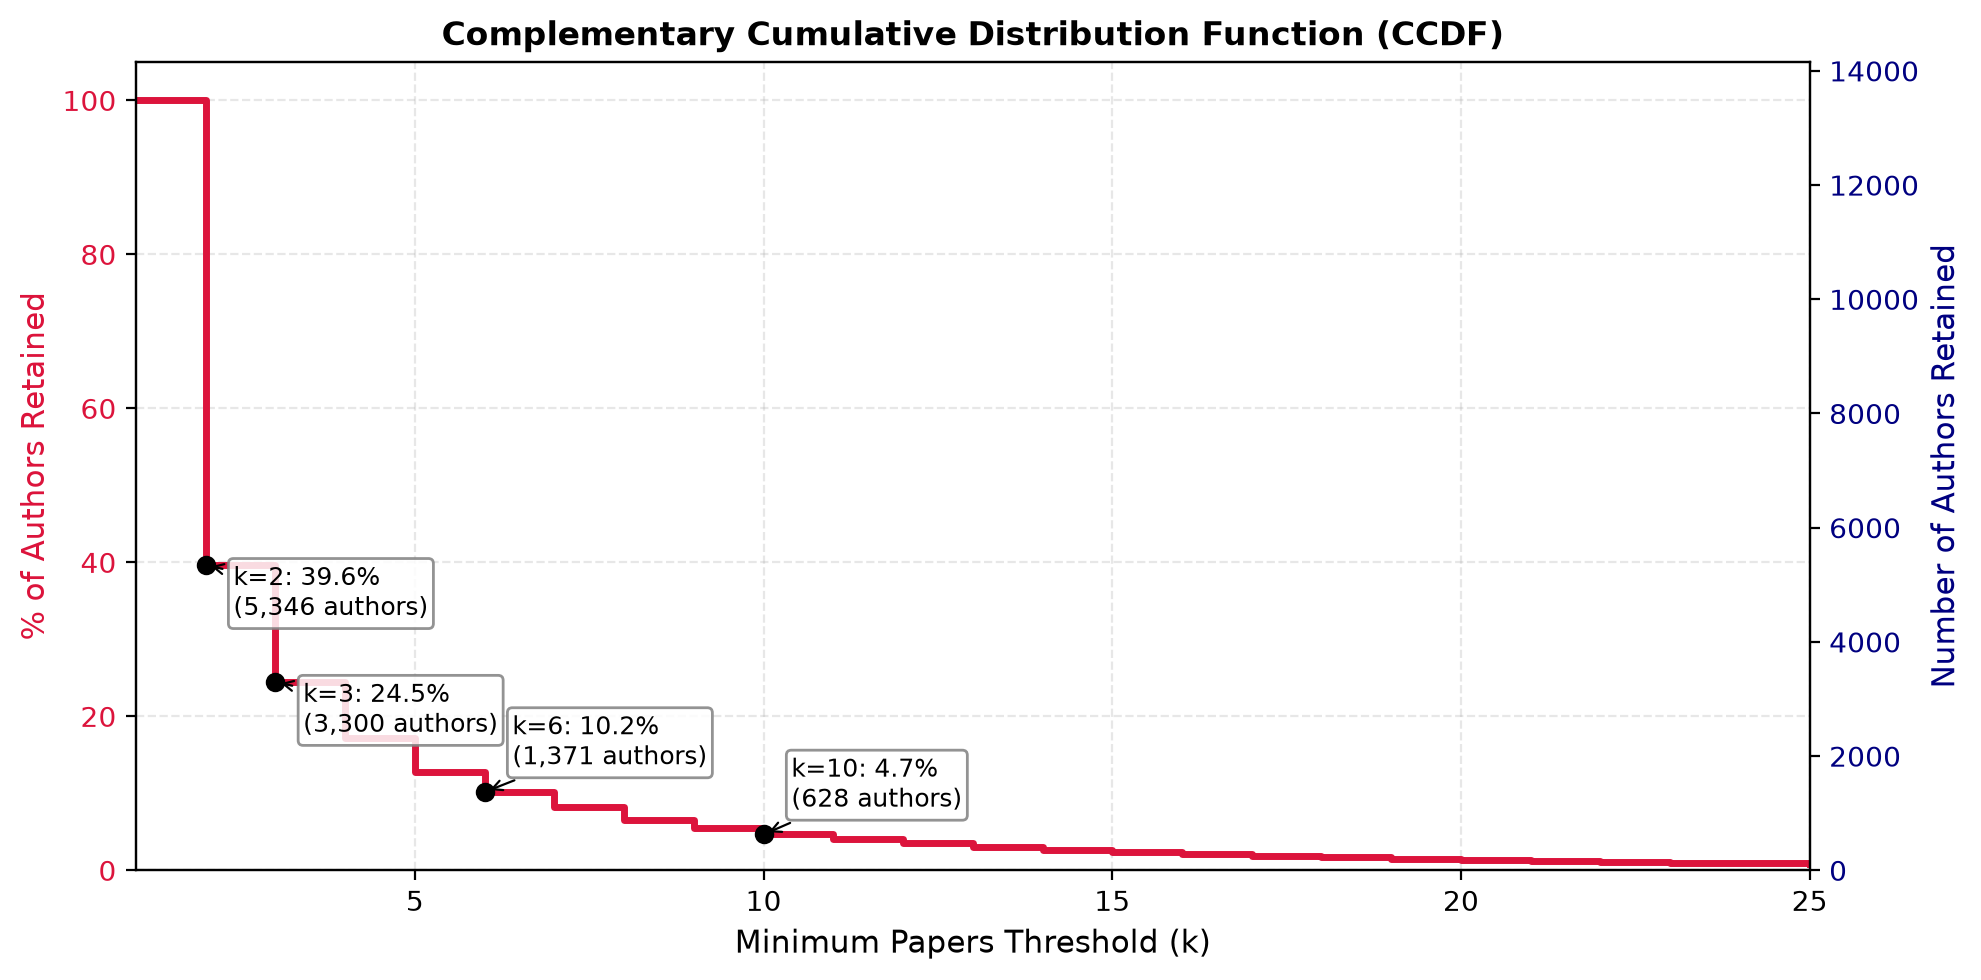

In [ ]:
paper_counts = last_author_df["num_papers"].values
n_total = len(paper_counts)

k_values = np.arange(1, 26)
retention_pct = np.array([(paper_counts >= k).mean() * 100 for k in k_values])

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.step(k_values, retention_pct, where="post", color="crimson", linewidth=2.5)
ax1.set_xlabel("Minimum Papers Threshold (k)", fontsize=11)
ax1.set_ylabel("% of Authors Retained", color="crimson", fontsize=11)
ax1.tick_params(axis="y", labelcolor="crimson")
ax1.set_xlim(1, 25)
ax1.set_ylim(0, 105)
ax1.grid(True, linestyle="--", alpha=0.3)


ax2 = ax1.twinx()
ax2.set_ylabel("Number of Authors Retained", color="navy", fontsize=11)
ax2.set_ylim(0, n_total * 1.05)
ax2.tick_params(axis="y", labelcolor="navy")

for k in [2, 3, 6, 10]:
    pct = (paper_counts >= k).mean() * 100
    cnt = (paper_counts >= k).sum()
    ax1.plot(k, pct, marker="o", markersize=6, color="black", zorder=5)
    ax1.annotate(
        f"k={k}: {pct:.1f}%\n({cnt:,} authors)",
        (k, pct),
        textcoords="offset points",
        xytext=(10, -18 if k in [2, 3] else 10),
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="gray", alpha=0.85),
        arrowprops=dict(arrowstyle="->", lw=0.8, color="black")
    )

plt.title("Complementary Cumulative Distribution Function (CCDF)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

For this inital analysis, we have decided to look at last listed authors who are part of 5 papers or more. This is because we want to study researchers who published more than 1 paper. These are the authors who decided to stay within a field and/or to change fields.

However, there are researchers who do not collaborate with other people. Are these independent researchers considered PIs? Let's look at the number of independent researchers in the dataset.

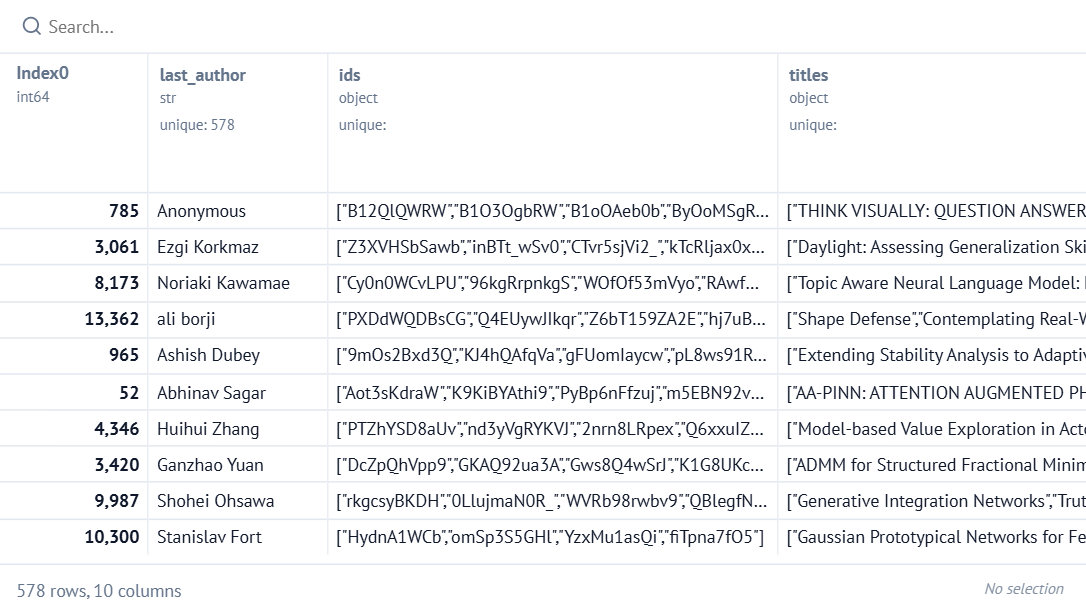

In [ ]:
solo_authors = last_author_df[last_author_df["collaborators"].apply(lambda collabs: all(len(c) == 0 for c in collabs))]
solo_authors.sort_values("num_papers", ascending=False)

In [ ]:
print(f"Authors with only solo papers: {len(solo_authors)}")
print(f"Average number of publications for solo-only authors: {solo_authors['num_papers'].mean():.2f}")

Authors with only solo papers: 578
Average number of publications for solo-only authors: 1.24


Here we will eliminate papers who list "Anonymous" as the author.

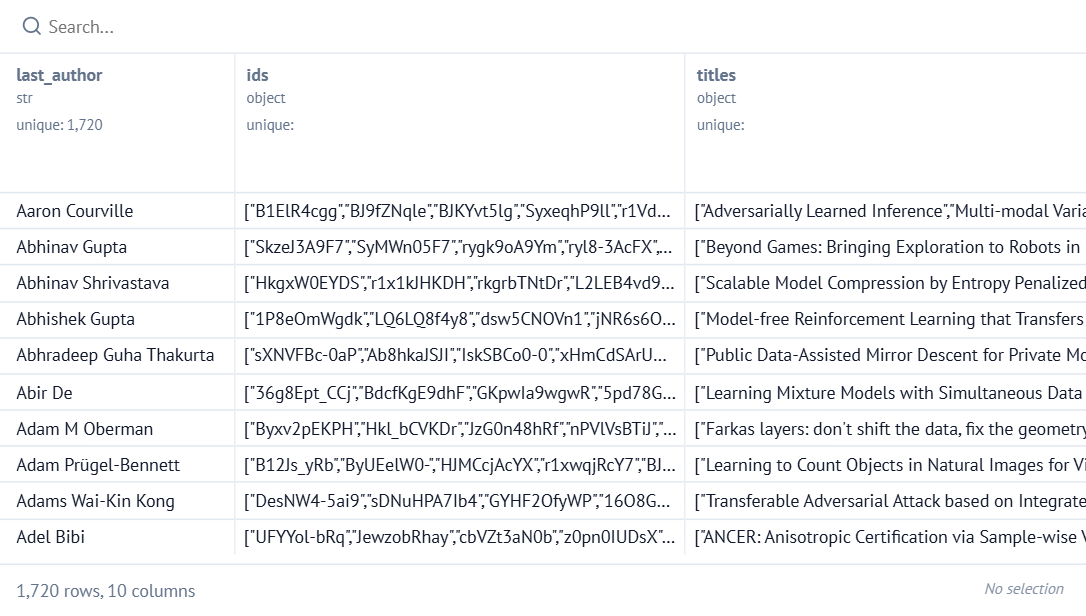

In [ ]:
threshold = 5
df = last_author_df[(last_author_df["num_papers"] >= threshold) & (last_author_df["last_author"] != "Anonymous")].reset_index(drop=True)
df

## Distribution of Papers per Author

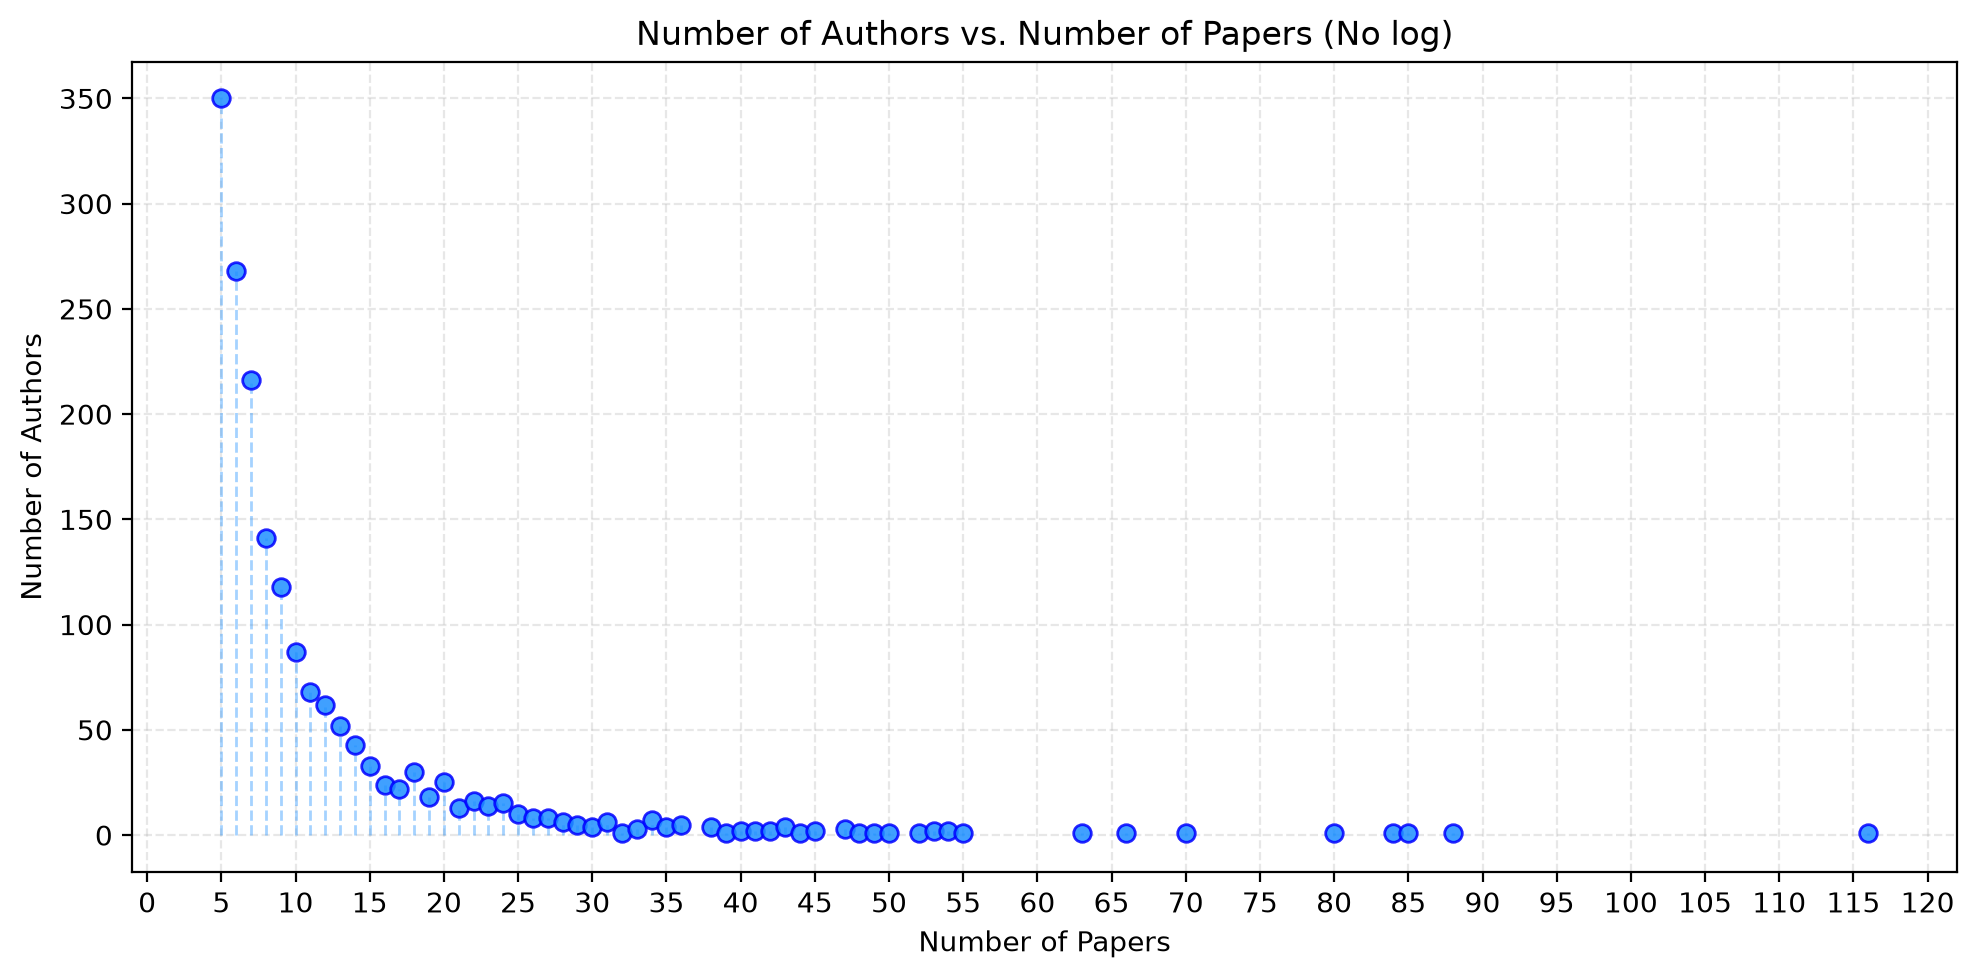

In [ ]:
paper_freq = df["num_papers"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.vlines(
    x=paper_freq.index,
    ymin=0,
    ymax=paper_freq.values,
    color="dodgerblue",
    linestyle="--",
    alpha=0.4,
    linewidth=1,
)
plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xticks(range(0, 125, 5))
plt.xlim(left=-1, right=122)
plt.title("Number of Authors vs. Number of Papers (No log)")
plt.xlabel("Number of Papers")
plt.ylabel("Number of Authors")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.gca()

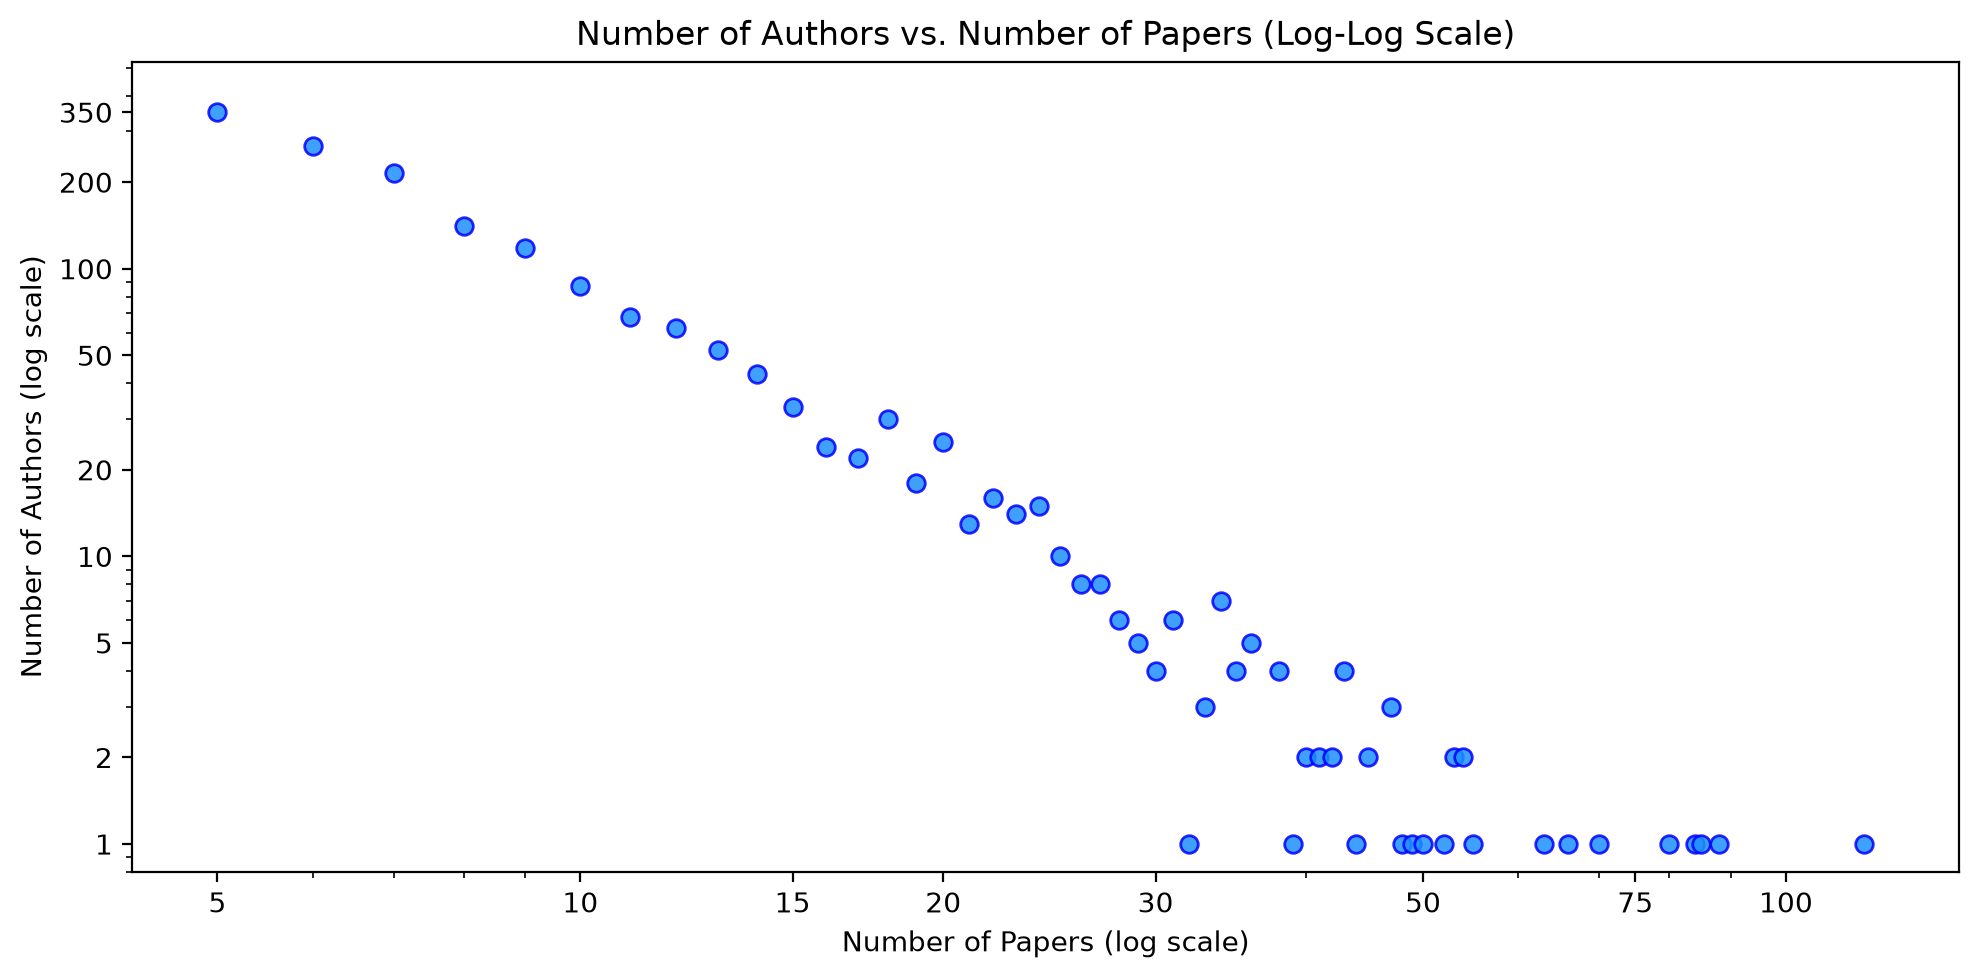

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    paper_freq.index,
    paper_freq.values,
    color="dodgerblue",
    edgecolor="blue",
    alpha=0.85,
    s=40,
    zorder=3,
)
plt.xscale("log")
plt.yscale("log")

plt.xlim(left=threshold * 0.85, right=paper_freq.index.max() * 1.2)
plt.ylim(bottom=0.8, top=paper_freq.values.max() * 1.5)

x_ticks = [5, 10, 15, 20, 30, 50, 75, 100]
plt.xticks(x_ticks, x_ticks)

y_ticks = [1, 2, 5, 10, 20, 50, 100, 200, 350]
plt.yticks(y_ticks, y_ticks)

plt.title("Number of Authors vs. Number of Papers (Log-Log Scale)")
plt.xlabel("Number of Papers (log scale)")
plt.ylabel("Number of Authors (log scale)")
plt.tight_layout()
plt.gca()

# Paper Representation: Recreating the Embeddings

The authors of the original paper used multiple models to convert the abstracts into representations. One approach was to use SBERT, which was shown to have the highest performance. The authors do not provide their weights, but fortunately they provide the code to recreate their embeddings.

In [ ]:
# Run the code below for the first time. It downloads the SBERT embeddings and output it in `output_dir`.
#
# output_path = "..."
#
# embedding_cls, embedding_sep, embedding_av = compute_text_embeddings_SBERT(
#     iclr2026v1["abstract"].tolist(),
#     output_path=output_path
# )

SBERT_embeddings_path = "data\embeddings_sbert"
_, _, embedding_av = compute_text_embeddings_SBERT(
    embeddings_path = SBERT_embeddings_path
)

In [ ]:
mo.md(r"""
The main pipeline from the paper is to first use SBERT then to use TSNE to map the SBERT's embeddings into a 2D space. 
""")

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">The main pipeline from the paper is to first use SBERT then to use TSNE to map the SBERT's embeddings into a 2D space. </span></span>

In [ ]:
tsne_av = compute_tsne(embeddings=embedding_av)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_jobs=-1, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 59.39 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 10.57 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.42 seconds
===> Running optimization with exaggeration=12.00, lr=4658.83 for 250 iterations...
Iteration   50, KL divergence 6.3887, 50 iterations in 3.4660 sec
Iteration  100, KL divergence 6.4941, 50 iterations in 3.9292 sec
Iteration  150, KL divergence 6.4934, 50 iterations in 3.8705 sec
Iteration  200, KL divergence 6.4933, 50 iterations in 3.6934 sec
Iteration  250, KL divergence 6.4932, 50 iterations in 3.9677 sec
   --> Time elapsed: 18.93 seconds
===> Running optimization with exaggerati

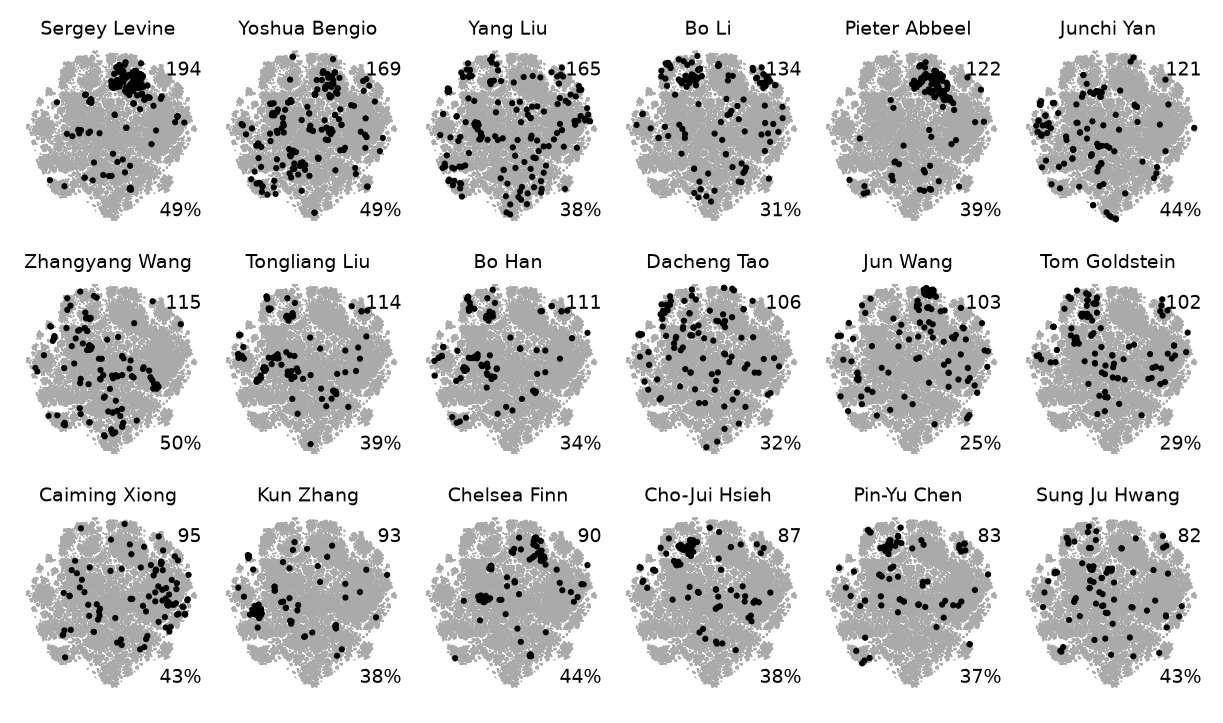

In [ ]:
# Strip and filter out empty or anonymous author strings
all_authors = [
    author.strip()
    for row in iclr2026v1.authors
    if row
    for author in row.split(', ')
    if author.strip() and author.strip() != "Anonymous"
]
authors, counts = np.unique(all_authors, return_counts=True)
ind = np.argsort(counts)[::-1]
top_authors = authors[ind]

fig_plot, axs = plt.subplots(nrows=3, ncols=6, figsize=(6.0, 3.5), layout='constrained')

for num, author in enumerate(top_authors[:18]):
    mask = [author in a.split(', ') for a in iclr2026v1.authors]
    
    axs.flat[num].axis('equal')
    axs.flat[num].scatter(*tsne_av.T, s=.5, ec='none', c='#aaaaaa', rasterized=True)
    axs.flat[num].scatter(*tsne_av[mask].T, s=5, ec='none', c='k', zorder=2)

    axs.flat[num].axis('off')
    axs.flat[num].set_title(f'{author}', fontsize=7, y=.92, x=.48)
    axs.flat[num].text(.99, .8, f'{np.sum(mask)}', ha='right', transform=axs.flat[num].transAxes, fontsize=7)
    
    accepted = np.array([d[:6]=='Accept' for d in iclr2026v1.decision])
    acceptance_rate = np.nanmean(accepted[mask]) * 100
    axs.flat[num].text(.99, .1, f'{acceptance_rate:.0f}%', fontsize=7, 
                       ha='right', transform=axs.flat[num].transAxes)
fig_plot
